# Types of ML Algorithms with scikit-learn — Lab Notebook
**AI-Enabled Systems Development · Companion to the "Types of ML Algorithms" deck**

This notebook walks through the major algorithm families in scikit-learn, using one consistent API:

| Part | Family | Dataset | Deck slides |
|---|---|---|---|
| 0 | The estimator API (`fit` / `predict` / `transform`, pipelines) | Iris | 4–6 |
| A | Supervised **classification** | Breast cancer, moons | 7–13 |
| B | Supervised **regression** | Diabetes | 14–16 |
| C | Unsupervised **clustering** | Blobs, moons | 17–19 |
| D | **Dimensionality reduction** | Digits | 20–21 |
| E | **Anomaly detection** | Synthetic | 22 |
| F | **Model selection & tuning** | Breast cancer | 23–24 |
| G | **Case study**: support-ticket triage | Synthetic tickets | 25–28 |
| H | Exercises | — | 29 |

**Requirements:** Python 3.9+, `scikit-learn>=1.3`, `numpy`, `pandas`, `matplotlib`. All datasets ship with scikit-learn or are generated here — no downloads.

> Run cells top to bottom. Every random process uses `RANDOM_STATE = 42`, so your numbers should match the deck.

In [1]:
# Setup
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

print("scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | numpy 2.5.3 | pandas 3.0.5


## Part 0 — One API for every algorithm
Every scikit-learn object is an **estimator** with the same interface:

- `fit(X, y)` — learn from data (`y` omitted for unsupervised)
- `predict(X)` — supervised models and some clusterers
- `transform(X)` — scalers, PCA, vectorizers
- `score(X, y)` — default metric (accuracy for classifiers, R² for regressors)

Hyper-parameters go in the constructor; learned attributes end with an underscore (`coef_`, `cluster_centers_`).

In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

scaler = StandardScaler().fit(X_train)          # transformer: learns mean_ and scale_
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)              # reuse TRAIN statistics -> no leakage

clf = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)   # estimator
print("learned coef_ shape:", clf.coef_.shape)
print("predictions:", clf.predict(X_test_s[:5]))
print("probabilities:\n", clf.predict_proba(X_test_s[:2]).round(3))
print("test accuracy:", round(clf.score(X_test_s, y_test), 3))

learned coef_ shape: (3, 4)
predictions: [0 1 1 1 0]
probabilities:
 [[0.985 0.015 0.   ]
 [0.034 0.621 0.345]]
test accuracy: 0.921


### Pipelines: preprocessing + model as one estimator
A `Pipeline` chains transformers and a final estimator. It is fitted on training folds only, which prevents data leakage during cross-validation.

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
scores = cross_val_score(pipe, X, y, cv=5)
print("5-fold accuracy:", scores.round(3), "mean =", round(scores.mean(), 3))

5-fold accuracy: [0.967 1.    0.933 0.9   1.   ] mean = 0.96


## Part A — Supervised classification
We compare seven classifiers on the Wisconsin breast-cancer dataset (569 samples, 30 numeric features, binary target). Distance- and margin-based models (kNN, SVM, logistic regression) get a `StandardScaler`; tree models don't need one.

In [4]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

Xc, yc = load_breast_cancer(return_X_y=True)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.2, stratify=yc, random_state=RANDOM_STATE)

classifiers = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "k-Nearest Neighbors": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "SVM (RBF kernel)":    make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0)),
    "Gaussian Naive Bayes": GaussianNB(),
    "Decision Tree":       DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in classifiers.items():
    res = cross_validate(model, Xc_train, yc_train, cv=cv, scoring=["accuracy", "f1"])
    rows.append({"model": name,
                 "cv_accuracy": res["test_accuracy"].mean(),
                 "cv_f1": res["test_f1"].mean(),
                 "acc_std": res["test_accuracy"].std(),
                 "fit_time_ms": 1000 * res["fit_time"].mean()})
clf_results = pd.DataFrame(rows).sort_values("cv_accuracy", ascending=False).reset_index(drop=True)
clf_results

,model,cv_accuracy,cv_f1,acc_std,fit_time_ms
0,Logistic Regression,0.978,0.983,0.010,5.204
1,SVM (RBF kernel),0.969,0.976,0.015,4.059
2,Random Forest,0.965,0.972,0.018,465.954
3,k-Nearest Neighbors,0.963,0.970,0.011,1.978
4,Hist Gradient Boosting,0.963,0.970,0.015,169.879
5,Gaussian Naive Bayes,0.941,0.953,0.025,1.262
6,Decision Tree,0.923,0.937,0.012,4.533


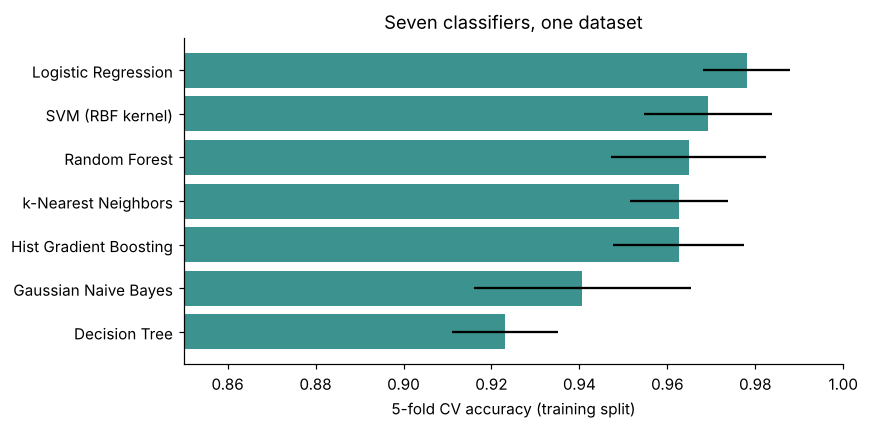

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(clf_results["model"], clf_results["cv_accuracy"], xerr=clf_results["acc_std"],
        color="#1A7F7A", alpha=0.85)
ax.invert_yaxis()
ax.set_xlim(0.85, 1.0)
ax.set_xlabel("5-fold CV accuracy (training split)")
ax.set_title("Seven classifiers, one dataset")
plt.tight_layout()
plt.show()

### How each family draws its decision boundary
On a 2-D "two moons" dataset we can *see* the inductive bias of each algorithm: linear models draw a straight line, kNN follows local density, trees cut axis-aligned boxes, and kernels/ensembles bend smoothly.

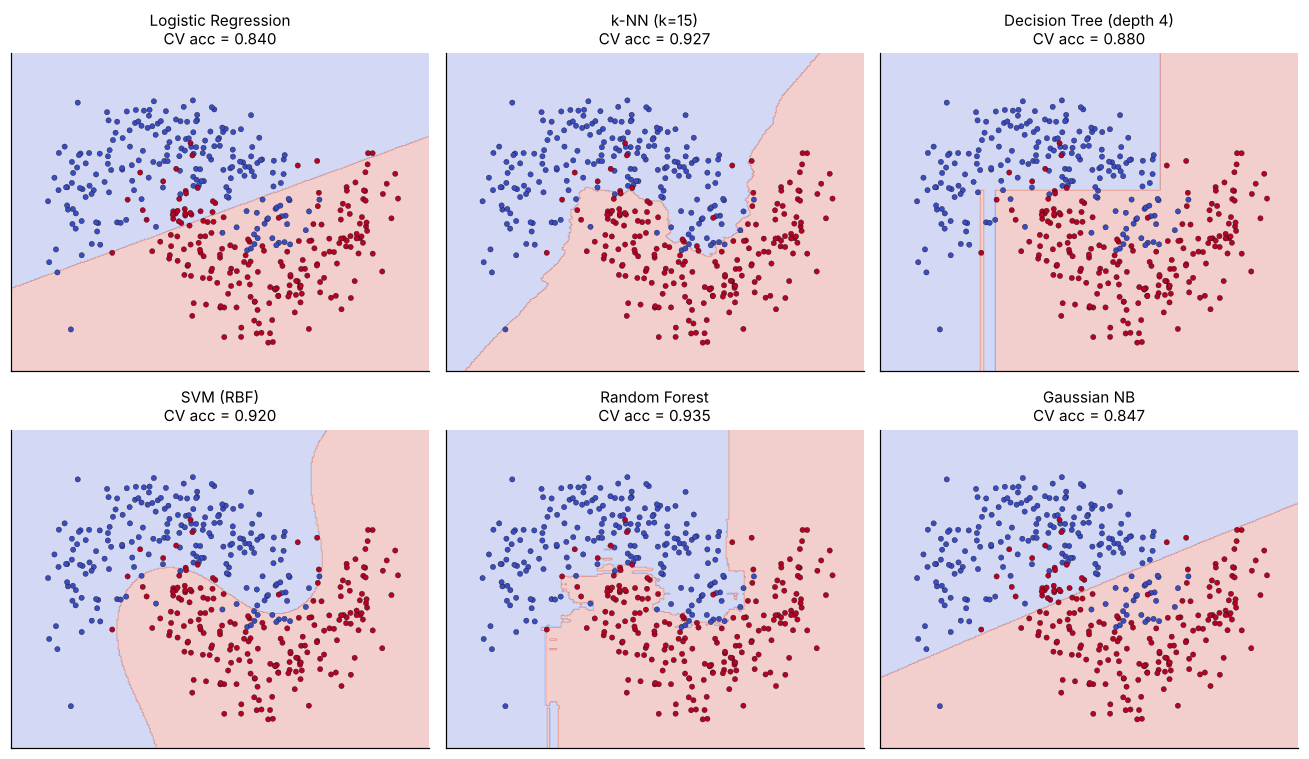

In [6]:
from sklearn.datasets import make_moons

Xm, ym = make_moons(n_samples=400, noise=0.25, random_state=RANDOM_STATE)
boundary_models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression()),
    "k-NN (k=15)":         make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
    "Decision Tree (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "SVM (RBF)":           make_pipeline(StandardScaler(), SVC(kernel="rbf")),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "Gaussian NB":         GaussianNB(),
}
xx, yy = np.meshgrid(np.linspace(-1.8, 2.8, 300), np.linspace(-1.3, 1.8, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
moons_acc = {}
for ax, (name, model) in zip(axes.ravel(), boundary_models.items()):
    model.fit(Xm, ym)
    moons_acc[name] = cross_val_score(model, Xm, ym, cv=5).mean()
    zz = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
    ax.scatter(Xm[:, 0], Xm[:, 1], c=ym, cmap="coolwarm", s=12, edgecolor="k", linewidth=0.2)
    ax.set_title(f"{name}\nCV acc = {moons_acc[name]:.3f}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

### Final check on the held-out test set
Cross-validation picked the candidates; the test set is touched **once**, at the end.

Best by CV: Logistic Regression  |  test accuracy = 0.982

              precision    recall  f1-score   support

   malignant      0.976     0.976     0.976        42
      benign      0.986     0.986     0.986        72

    accuracy                          0.982       114
   macro avg      0.981     0.981     0.981       114
weighted avg      0.982     0.982     0.982       114



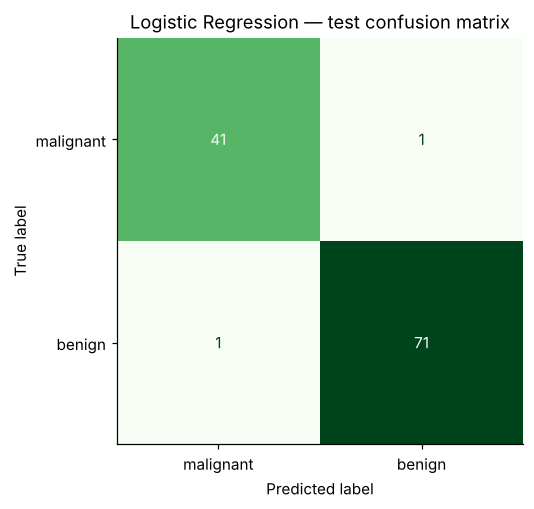

In [7]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

best_clf_name = clf_results.loc[0, "model"]
best_clf = classifiers[best_clf_name].fit(Xc_train, yc_train)
yc_pred = best_clf.predict(Xc_test)
clf_test_acc = (yc_pred == yc_test).mean()
print(f"Best by CV: {best_clf_name}  |  test accuracy = {clf_test_acc:.3f}\n")
print(classification_report(yc_test, yc_pred, target_names=["malignant", "benign"], digits=3))

ConfusionMatrixDisplay(confusion_matrix(yc_test, yc_pred),
                       display_labels=["malignant", "benign"]).plot(cmap="Greens", colorbar=False)
plt.title(f"{best_clf_name} — test confusion matrix")
plt.show()

## Part B — Supervised regression
The diabetes dataset has 442 patients, 10 standardized features, and a continuous target (disease progression after one year). We compare linear, regularized, instance-based, kernel, and ensemble regressors with R² and MAE.

In [8]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

diab = load_diabetes()
Xr, yr = diab.data, diab.target

regressors = {
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=0.05)": Ridge(alpha=0.05),
    "Lasso (alpha=0.05)": Lasso(alpha=0.05),
    "k-NN Regressor":    make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=15)),
    "SVR (RBF, C=100)":  make_pipeline(StandardScaler(), SVR(C=100, epsilon=5)),
    "Random Forest":     RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, random_state=RANDOM_STATE),
}
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in regressors.items():
    res = cross_validate(model, Xr, yr, cv=kf, scoring=["r2", "neg_mean_absolute_error"])
    rows.append({"model": name, "cv_r2": res["test_r2"].mean(),
                 "cv_mae": -res["test_neg_mean_absolute_error"].mean()})
reg_results = pd.DataFrame(rows).sort_values("cv_r2", ascending=False).reset_index(drop=True)
reg_results

,model,cv_r2,cv_mae
0,Lasso (alpha=0.05),0.480,44.458
1,Ridge (alpha=0.05),0.480,44.352
2,Linear Regression,0.478,44.270
3,Hist Gradient Boosting,0.462,45.048
4,"SVR (RBF, C=100)",0.455,43.852
5,Random Forest,0.442,46.207
6,k-NN Regressor,0.433,46.354


### Regularization: Ridge shrinks, Lasso selects
Ridge (L2) pulls all coefficients toward zero; Lasso (L1) drives some *exactly* to zero, performing feature selection.

Features Lasso set to zero: ['age', 's2', 's4']


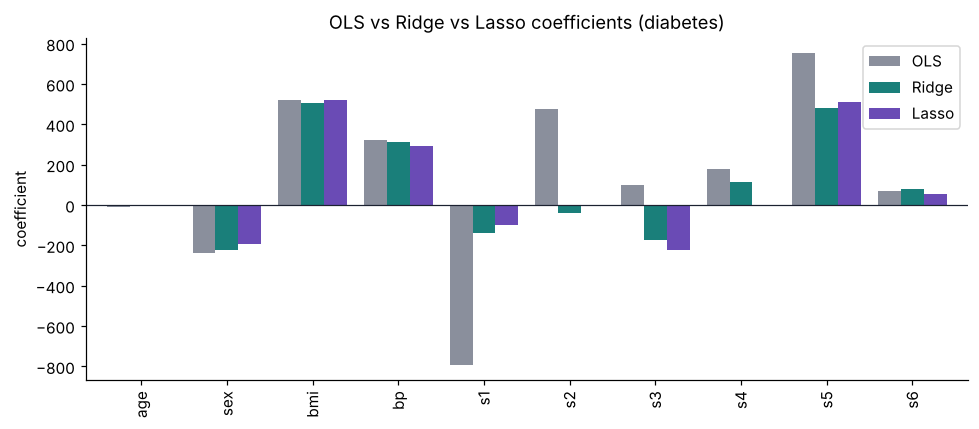

,OLS,Ridge,Lasso
age,-10.0,-2.7,-0.0
sex,-239.8,-221.3,-194.0
bmi,519.8,507.6,521.8
bp,324.4,311.5,295.2
s1,-792.2,-138.0,-99.4
s2,476.7,-37.0,-0.0
s3,101.0,-174.6,-222.7
s4,177.1,113.6,0.0
s5,751.3,483.1,512.0
s6,67.6,79.2,52.9


In [9]:
coefs = pd.DataFrame({
    "OLS":   LinearRegression().fit(Xr, yr).coef_,
    "Ridge": Ridge(alpha=0.05).fit(Xr, yr).coef_,
    "Lasso": Lasso(alpha=0.05).fit(Xr, yr).coef_,
}, index=diab.feature_names)
lasso_zeroed = list(coefs.index[coefs["Lasso"].abs() < 1e-9])
print("Features Lasso set to zero:", lasso_zeroed)

coefs.plot.bar(figsize=(9, 4), color=["#8A8F9C", "#1A7F7A", "#6A4BB5"], width=0.8)
plt.axhline(0, color="#1B2130", lw=0.8)
plt.ylabel("coefficient")
plt.title("OLS vs Ridge vs Lasso coefficients (diabetes)")
plt.tight_layout()
plt.show()
coefs.round(1)

## Part C — Unsupervised clustering
No labels during fitting. We run three clustering families on two shapes of data:
- **K-Means** — centroid-based; assumes roughly spherical, similar-size clusters; you pick `k`.
- **DBSCAN** — density-based; finds arbitrary shapes and labels noise as `-1`; you pick `eps`.
- **Agglomerative** — hierarchical merging; `linkage` controls cluster shape.

Because these are toy datasets we *do* know the true groups, so we can report the Adjusted Rand Index (ARI, 1.0 = perfect agreement) alongside the label-free silhouette score.

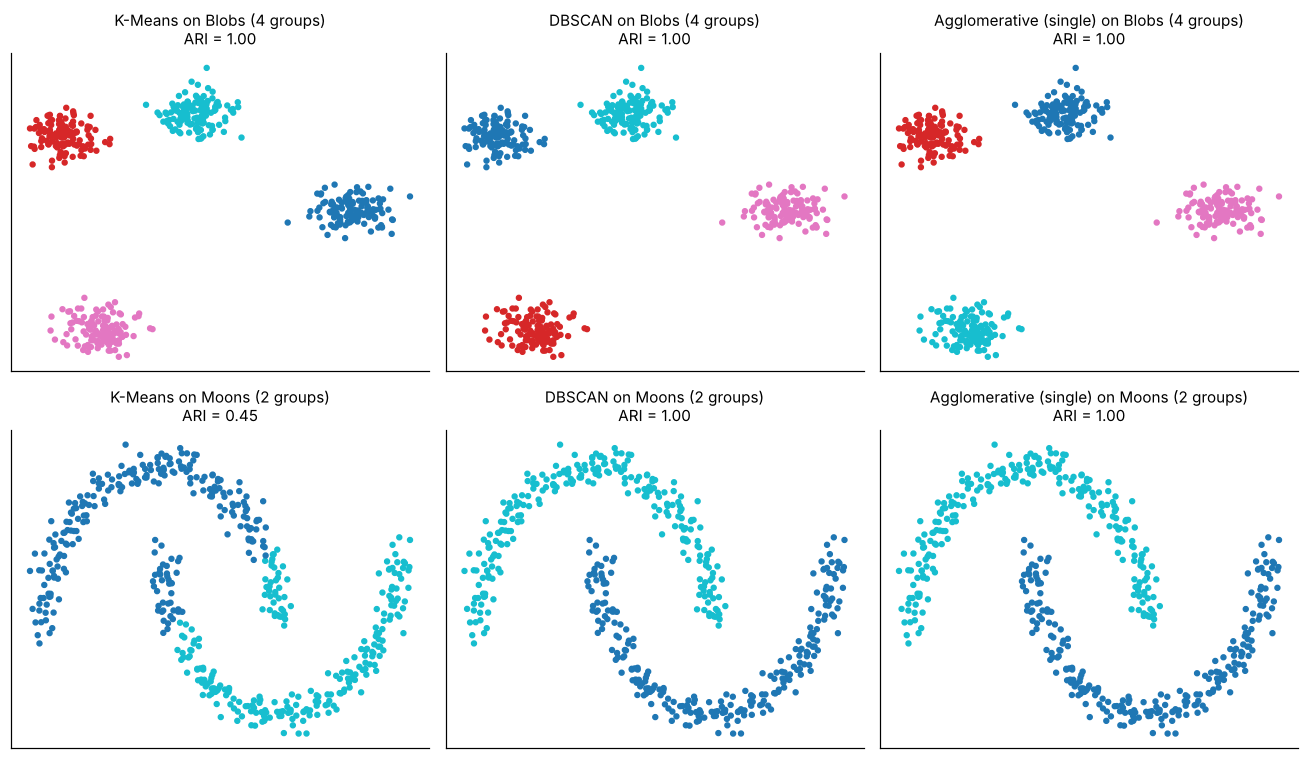

,data,algorithm,clusters_found,noise_pts,silhouette,ARI
0,Blobs (4 groups),K-Means,4,0,0.819,1.00
1,Blobs (4 groups),DBSCAN,4,0,0.819,1.00
2,Blobs (4 groups),Agglomerative (single),4,0,0.819,1.00
3,Moons (2 groups),K-Means,2,0,0.495,0.45
4,Moons (2 groups),DBSCAN,2,0,0.388,1.00
5,Moons (2 groups),Agglomerative (single),2,0,0.388,1.00


In [10]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

Xb, yb = make_blobs(n_samples=500, centers=4, cluster_std=0.9, random_state=RANDOM_STATE)
Xmo, ymo = make_moons(n_samples=500, noise=0.06, random_state=RANDOM_STATE)
datasets = {"Blobs (4 groups)": (StandardScaler().fit_transform(Xb), yb, 4),
            "Moons (2 groups)": (StandardScaler().fit_transform(Xmo), ymo, 2)}

def clusterers(k):
    return {"K-Means": KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE),
            "DBSCAN": DBSCAN(eps=0.3, min_samples=5),
            "Agglomerative (single)": AgglomerativeClustering(n_clusters=k, linkage="single")}

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
rows = []
for r, (dname, (Xd, yd, k)) in enumerate(datasets.items()):
    for c, (cname, algo) in enumerate(clusterers(k).items()):
        labels = algo.fit_predict(Xd)
        n_found = len(set(labels) - {-1})
        sil = silhouette_score(Xd, labels) if n_found > 1 else np.nan
        ari = adjusted_rand_score(yd, labels)
        rows.append({"data": dname, "algorithm": cname, "clusters_found": n_found,
                     "noise_pts": int((labels == -1).sum()), "silhouette": sil, "ARI": ari})
        ax = axes[r, c]
        ax.scatter(Xd[:, 0], Xd[:, 1], c=labels, cmap="tab10", s=10)
        ax.set_title(f"{cname} on {dname}\nARI = {ari:.2f}", fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()
cluster_results = pd.DataFrame(rows)
cluster_results

### Choosing `k` for K-Means: elbow and silhouette
Inertia always falls as `k` grows; look for the elbow. Silhouette peaks at the most natural `k`.

k with best silhouette: 4


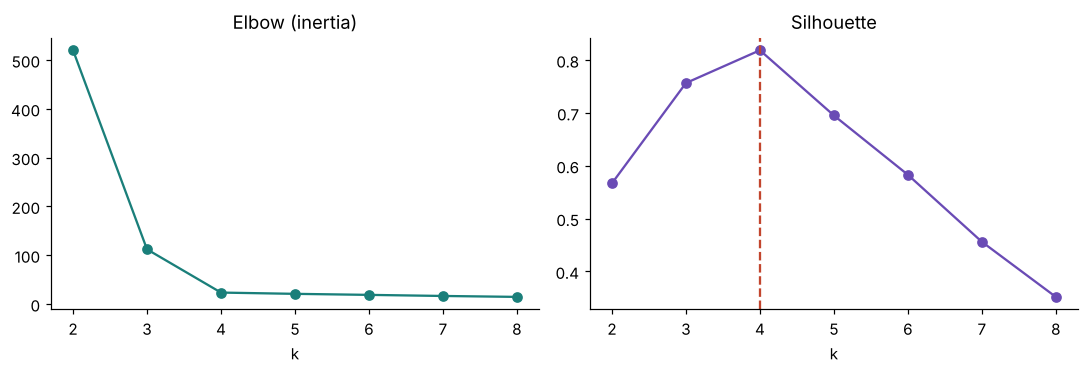

In [11]:
Xb_s = datasets["Blobs (4 groups)"][0]
ks = range(2, 9)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xb_s)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Xb_s, km.labels_))
best_k = list(ks)[int(np.argmax(sils))]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.5))
a1.plot(list(ks), inertias, "o-", color="#1A7F7A"); a1.set(title="Elbow (inertia)", xlabel="k")
a2.plot(list(ks), sils, "o-", color="#6A4BB5"); a2.set(title="Silhouette", xlabel="k")
a2.axvline(best_k, ls="--", color="#C2452D")
plt.tight_layout(); plt.show()
print("k with best silhouette:", best_k)

## Part D — Dimensionality reduction with PCA
The digits dataset has 1,797 8×8 images (64 features). PCA finds orthogonal directions of maximum variance; we keep enough components to explain most of the variance and often lose little accuracy.

Components needed for 90% variance: 31 of 64


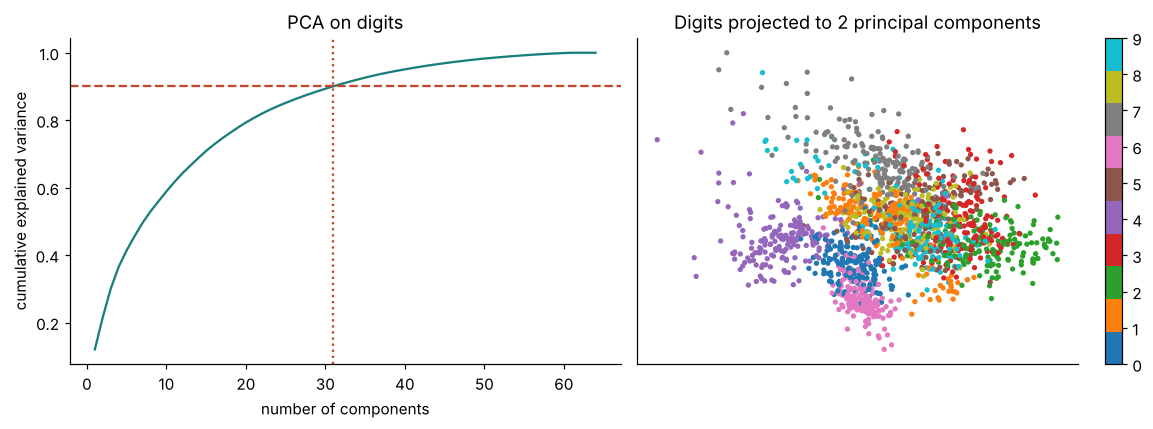

In [12]:
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA

Xd, yd = load_digits(return_X_y=True)
pca_full = PCA().fit(StandardScaler().fit_transform(Xd))
cumvar = np.cumsum(pca_full.explained_variance_ratio_)
n90 = int(np.argmax(cumvar >= 0.90) + 1)
print(f"Components needed for 90% variance: {n90} of {Xd.shape[1]}")

X2 = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(Xd))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(range(1, 65), cumvar, color="#1A7F7A"); a1.axhline(0.9, ls="--", color="#C2452D")
a1.axvline(n90, ls=":", color="#C2452D")
a1.set(xlabel="number of components", ylabel="cumulative explained variance", title="PCA on digits")
sc = a2.scatter(X2[:, 0], X2[:, 1], c=yd, cmap="tab10", s=6)
a2.set(title="Digits projected to 2 principal components", xticks=[], yticks=[])
plt.colorbar(sc, ax=a2, ticks=range(10))
plt.tight_layout(); plt.show()

In [13]:
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    Xd, yd, test_size=0.25, stratify=yd, random_state=RANDOM_STATE)
pca_rows = []
for n in [2, 5, 10, 20, n90, 64]:
    p = make_pipeline(StandardScaler(), PCA(n_components=n), LogisticRegression(max_iter=2000))
    p.fit(Xd_train, yd_train)
    pca_rows.append({"n_components": n, "test_accuracy": p.score(Xd_test, yd_test)})
pca_results = pd.DataFrame(pca_rows).drop_duplicates("n_components")
pca_results

,n_components,test_accuracy
0,2,0.511
1,5,0.784
2,10,0.858
3,20,0.942
4,31,0.949
5,64,0.976


## Part E — Anomaly detection
Train on mostly-normal data and flag points that don't fit. We inject 5% outliers so we can measure precision and recall.

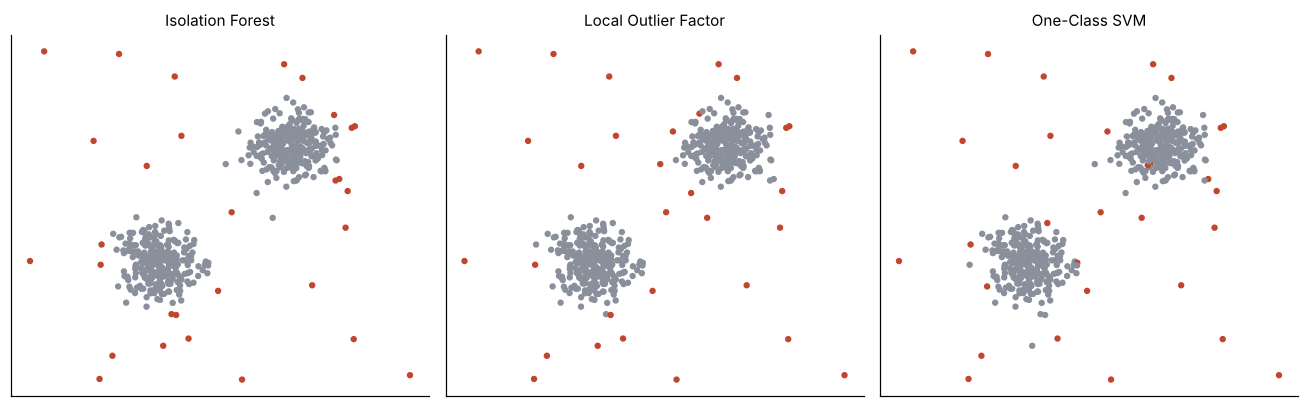

,detector,flagged,precision,recall
0,Isolation Forest,30,0.700,0.700
1,Local Outlier Factor,30,0.767,0.767
2,One-Class SVM,31,0.710,0.733


In [14]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.metrics import precision_score, recall_score

rng = np.random.RandomState(RANDOM_STATE)
inliers = np.r_[rng.normal(0, 0.6, (285, 2)) + [2, 2], rng.normal(0, 0.6, (285, 2)) - [2, 2]]
outliers = rng.uniform(-6, 6, (30, 2))
Xa = np.r_[inliers, outliers]
ya_true = np.r_[np.zeros(len(inliers)), np.ones(len(outliers))]   # 1 = anomaly

detectors = {
    "Isolation Forest": IsolationForest(contamination=0.05, random_state=RANDOM_STATE),
    "Local Outlier Factor": LocalOutlierFactor(n_neighbors=20, contamination=0.05),
    "One-Class SVM": OneClassSVM(nu=0.05, gamma=0.3),
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
rows = []
for ax, (name, det) in zip(axes, detectors.items()):
    flag = (det.fit_predict(Xa) == -1).astype(int)        # sklearn returns -1 for outliers
    rows.append({"detector": name, "flagged": flag.sum(),
                 "precision": precision_score(ya_true, flag), "recall": recall_score(ya_true, flag)})
    ax.scatter(Xa[:, 0], Xa[:, 1], c=np.where(flag, "#C2452D", "#8A8F9C"), s=10)
    ax.set_title(name, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()
anomaly_results = pd.DataFrame(rows)
anomaly_results

## Part F — Model selection and tuning
`GridSearchCV` tries every hyper-parameter combination with cross-validation and refits the best one. Pipeline parameters use the `step__param` naming convention.

best params: {'svc__C': 10, 'svc__gamma': 0.01}
best CV accuracy: 0.976
test accuracy of refit best model: 0.982


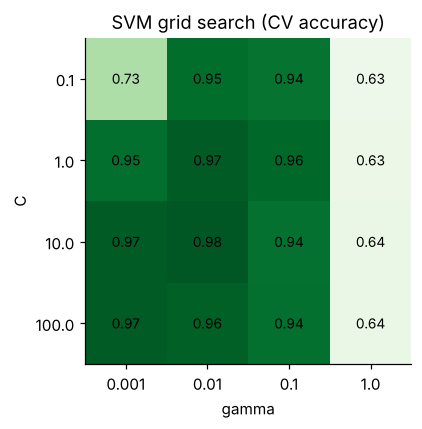

In [15]:
from sklearn.model_selection import GridSearchCV

svm_pipe = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
param_grid = {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.001, 0.01, 0.1, 1]}
grid_search = GridSearchCV(svm_pipe, param_grid, cv=cv, scoring="accuracy", n_jobs=1)
grid_search.fit(Xc_train, yc_train)

print("best params:", grid_search.best_params_)
print(f"best CV accuracy: {grid_search.best_score_:.3f}")
gs_test_acc = grid_search.score(Xc_test, yc_test)
print(f"test accuracy of refit best model: {gs_test_acc:.3f}")

heat = pd.DataFrame(grid_search.cv_results_)[["param_svc__C", "param_svc__gamma", "mean_test_score"]] \
         .pivot(index="param_svc__C", columns="param_svc__gamma", values="mean_test_score")
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(heat.values, cmap="Greens", vmin=0.6, vmax=1.0)
ax.set_xticks(range(4), heat.columns); ax.set_yticks(range(4), heat.index)
ax.set_xlabel("gamma"); ax.set_ylabel("C"); ax.set_title("SVM grid search (CV accuracy)")
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{heat.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.tight_layout(); plt.show()

### Bias–variance: validation curve for tree depth
Shallow trees underfit (both scores low); deep trees overfit (training score → 1.0, validation drops or plateaus).

best max_depth by validation accuracy: 2


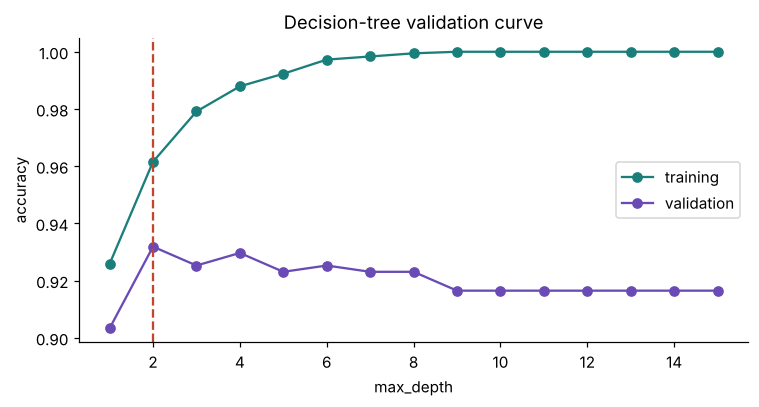

In [16]:
from sklearn.model_selection import validation_curve

depths = np.arange(1, 16)
train_sc, val_sc = validation_curve(
    DecisionTreeClassifier(random_state=RANDOM_STATE), Xc_train, yc_train,
    param_name="max_depth", param_range=depths, cv=cv)
best_depth = int(depths[val_sc.mean(axis=1).argmax()])

plt.figure(figsize=(7, 3.8))
plt.plot(depths, train_sc.mean(axis=1), "o-", label="training", color="#1A7F7A")
plt.plot(depths, val_sc.mean(axis=1), "o-", label="validation", color="#6A4BB5")
plt.axvline(best_depth, ls="--", color="#C2452D")
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.legend(); plt.title("Decision-tree validation curve")
plt.tight_layout(); plt.show()
print("best max_depth by validation accuracy:", best_depth)

## Part G — Case study: support-ticket triage (our running example)
Same problem as Modules 1–2 and the Intro-to-ML lab: route an incoming ticket to the right queue. Here we ask **which algorithm family** works best on TF-IDF text features, and whether *unsupervised* clustering can rediscover the categories without labels.

The tickets are synthetic (generated from templates with deliberate overlap and ~5% label noise) so results are reproducible. Swap in your own data by replacing `tickets` with a DataFrame that has `text` and `category` columns.

In [17]:
rng = np.random.RandomState(RANDOM_STATE)
templates = {
    "billing": ["I was charged twice for my {plan} subscription", "refund request for invoice {num}",
                "my credit card was billed after I cancelled", "why did my {plan} plan price go up",
                "need a copy of the receipt for order {num}", "payment failed but money left my account",
                "update billing address on my account", "discount code was not applied at checkout"],
    "account": ["cannot log in after resetting my password", "locked out of my account after {num} attempts",
                "two-factor code never arrives on my phone", "please change the email on my account",
                "how do I delete my account and data", "single sign-on stopped working for our team",
                "password reset link expired", "add a new admin user to our {plan} workspace"],
    "bug": ["the app crashes when I upload a file", "error {num} when saving the dashboard",
            "export to CSV produces an empty file", "page keeps loading forever on {browser}",
            "sync between mobile and web is broken", "the search returns wrong results since the update",
            "notifications are duplicated after the latest release", "API returns 500 error on the {plan} tier"],
    "feature": ["please add dark mode to the dashboard", "can you support exporting to PDF",
                "would love an integration with {tool}", "request: bulk edit for tickets",
                "allow custom fields on the {plan} plan", "add keyboard shortcuts for power users",
                "it would help to schedule reports weekly", "suggestion: let us tag tickets by team"],
    "shipping": ["my order {num} has not arrived yet", "tracking number shows no updates for a week",
                 "package was delivered to the wrong address", "item arrived damaged, need a replacement",
                 "can I change the delivery date for order {num}", "shipping cost seems too high to {country}",
                 "only part of my order was delivered", "return label for order {num} is not working"],
}
fill = {"plan": ["basic", "pro", "enterprise", "team"], "num": [str(n) for n in range(100, 999, 37)],
        "browser": ["Chrome", "Safari", "Firefox", "Edge"], "tool": ["Slack", "Jira", "Salesforce", "Zapier"],
        "country": ["Canada", "Germany", "Japan", "Brazil"]}
openers = ["", "hi team, ", "hello, ", "urgent: ", "quick question - ", "not happy. ", "please help, "]
closers = ["", " thanks", " asap please", " this is the second time", " any update?", " for my account"]

# Cross-queue context phrases make the task realistically ambiguous
context = ["after the update", "on my account", "for order {num}", "since I upgraded to {plan}",
           "on the mobile app", "and I was charged", "the invoice page", "my team cannot work"]

def make_ticket(cat):
    t = rng.choice(templates[cat])
    if rng.rand() < 0.45:                                  # borrow context from anywhere
        t += " " + rng.choice(context)
    for key, vals in fill.items():
        t = t.replace("{" + key + "}", rng.choice(vals))
    words = [w for w in t.split() if rng.rand() > 0.25]     # people write in fragments
    return (rng.choice(openers) + " ".join(words) + rng.choice(closers)).strip()

cats = list(templates)
labels = rng.choice(cats, size=1500)
texts = [make_ticket(c) for c in labels]
noisy = rng.rand(len(labels)) < 0.05                      # 5% mislabeled, like real triage logs
labels = np.where(noisy, rng.choice(cats, size=len(labels)), labels)
tickets = pd.DataFrame({"text": texts, "category": labels})
print(tickets.shape); print(tickets["category"].value_counts().to_dict())
tickets.sample(6, random_state=RANDOM_STATE)

(1500, 2)
{'billing': 311, 'shipping': 305, 'account': 296, 'bug': 295, 'feature': 293}


,text,category
1116,"please help, request: edit the this is the second time",feature
1368,quick question - add keyboard shortcuts power since I upgraded to team asap please,feature
422,not happy. locked of my account after 988 attempts any update?,account
413,not happy. request: bulk edit for tickets this is the second time,feature
451,allow fields on the basic plan after the update thanks,feature
861,"hi team, two-factor code never on my phone this is the second time",account


In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    tickets["text"], tickets["category"], test_size=0.2, stratify=tickets["category"], random_state=RANDOM_STATE)

def tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, stop_words="english")

text_models = {
    "Multinomial NB":      make_pipeline(tfidf(), MultinomialNB(alpha=0.1)),
    "Logistic Regression": make_pipeline(tfidf(), LogisticRegression(max_iter=2000, C=5)),
    "Linear SVM":          make_pipeline(tfidf(), LinearSVC(C=0.5)),
    "k-NN (cosine)":       make_pipeline(tfidf(), KNeighborsClassifier(n_neighbors=7, metric="cosine")),
    "Random Forest":       make_pipeline(tfidf(), RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)),
}
rows = []
for name, model in text_models.items():
    res = cross_validate(model, Xt_train, yt_train, cv=cv, scoring=["accuracy", "f1_macro"])
    rows.append({"model": name, "cv_accuracy": res["test_accuracy"].mean(),
                 "cv_macro_f1": res["test_f1_macro"].mean(), "fit_time_ms": 1000 * res["fit_time"].mean()})
ticket_results = pd.DataFrame(rows).sort_values("cv_macro_f1", ascending=False).reset_index(drop=True)
ticket_results

,model,cv_accuracy,cv_macro_f1,fit_time_ms
0,Linear SVM,0.947,0.947,23.402
1,Multinomial NB,0.938,0.938,17.616
2,Logistic Regression,0.938,0.938,47.050
3,k-NN (cosine),0.929,0.929,17.381
4,Random Forest,0.928,0.929,928.661


Note the ceiling: with ~5% of labels randomly reassigned, no model can be "right" on those tickets, so accuracy around 0.93–0.95 is close to the best achievable. Real triage data behaves the same way.

Linear SVM — test accuracy 0.930

              precision    recall  f1-score   support

     account      0.889     0.949     0.918        59
     billing      0.922     0.952     0.937        62
         bug      0.966     0.949     0.957        59
     feature      0.930     0.898     0.914        59
    shipping      0.948     0.902     0.924        61

    accuracy                          0.930       300
   macro avg      0.931     0.930     0.930       300
weighted avg      0.931     0.930     0.930       300



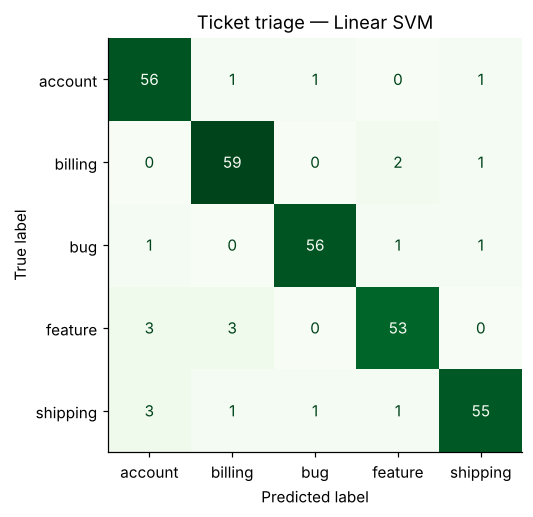

In [19]:
best_text_name = ticket_results.loc[0, "model"]
best_text = text_models[best_text_name].fit(Xt_train, yt_train)
yt_pred = best_text.predict(Xt_test)
ticket_test_acc = (yt_pred == yt_test).mean()
print(f"{best_text_name} — test accuracy {ticket_test_acc:.3f}\n")
print(classification_report(yt_test, yt_pred, digits=3))
ConfusionMatrixDisplay.from_predictions(yt_test, yt_pred, cmap="Greens", colorbar=False)
plt.title(f"Ticket triage — {best_text_name}")
plt.tight_layout(); plt.show()

In [20]:
# Which words drive each category? (interpretability from the linear model)
lr_pipe = text_models["Logistic Regression"].fit(Xt_train, yt_train)
vocab = np.array(lr_pipe[0].get_feature_names_out())
lr = lr_pipe[-1]
top_terms = {c: list(vocab[np.argsort(lr.coef_[i])[::-1][:6]]) for i, c in enumerate(lr.classes_)}
pd.DataFrame(top_terms)

,account,billing,bug,feature,shipping
0,data,refund,error,tickets,arrived
1,phone,copy,file,schedule,order
2,locked,did,returns,love,delivered
3,attempts,price,dashboard,custom,package
4,password,receipt,notifications,exporting,shipping
5,factor,left,sync,add,date


In [21]:
# Unsupervised view: can K-Means rediscover the five queues without labels?
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def cluster_tickets(stop_words, k=5):
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, stop_words=stop_words)
    Xtf = vec.fit_transform(tickets["text"])
    lsa = make_pipeline(TruncatedSVD(n_components=50, random_state=RANDOM_STATE), Normalizer(copy=False))
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(lsa.fit_transform(Xtf))
    centroids = lsa[0].inverse_transform(km.cluster_centers_)
    terms = vec.get_feature_names_out()
    tops = [", ".join(terms[np.argsort(centroids[j])[::-1][:5]]) for j in range(k)]
    return adjusted_rand_score(tickets["category"], km.labels_), km.labels_, tops

def show(title, ari, labels, tops):
    print(f"{title}: ARI vs true categories = {ari:.2f}")
    for j, top in enumerate(tops):
        majority = tickets["category"][labels == j].value_counts().idxmax()
        print(f"  cluster {j} (mostly {majority:8s}): {top}")

# Pass 1: generic English stop words only
ticket_ari_raw, labels_raw, tops_raw = cluster_tickets("english")
show("Pass 1 - generic stop words", ticket_ari_raw, labels_raw, tops_raw)

Pass 1 - generic stop words: ARI vs true categories = 0.04
  cluster 0 (mostly bug     ): account, update, thanks, hello, asap
  cluster 1 (mostly feature ): hi, hi team, team, account, update
  cluster 2 (mostly feature ): quick question, quick, question, update, account
  cluster 3 (mostly shipping): order, arrived, need, update, urgent
  cluster 4 (mostly account ): time, second, second time, team, help


Pass 1 clusters on **greetings and sign-offs** ("hi team", "asap", "second time") — the biggest source of variation in the text, but irrelevant to routing. Clustering optimizes *similarity*, not *your business question*. The fix is domain knowledge: add boilerplate words to the stop list.

In [22]:
# Pass 2: add domain boilerplate to the stop list
boilerplate = {"hi", "team", "hello", "urgent", "quick", "question", "happy", "help", "thanks",
               "asap", "second", "time", "update", "account"}
ticket_ari, labels_clean, tops_clean = cluster_tickets(list(ENGLISH_STOP_WORDS | boilerplate))
show("Pass 2 - domain stop words", ticket_ari, labels_clean, tops_clean)

Pass 2 - domain stop words: ARI vs true categories = 0.16
  cluster 0 (mostly feature ): tickets, request, bulk, tag, request bulk
  cluster 1 (mostly bug     ): dashboard, error, attempts, locked, email
  cluster 2 (mostly bug     ): wrong, address, custom, search, allow
  cluster 3 (mostly billing ): charged, file, invoice, app, password
  cluster 4 (mostly shipping): order, arrived, need, billing, delivery


In [23]:
# Use the trained model on new tickets
new_tickets = ["I got billed for the pro plan twice this month",
               "the export button gives an error since yesterday",
               "could you add a Slack integration for alerts",
               "my parcel says delivered but nothing is here",
               "can't sign in, the reset email never came"]
for t, p in zip(new_tickets, best_text.predict(new_tickets)):
    print(f"{p:9s} <- {t}")

billing   <- I got billed for the pro plan twice this month
bug       <- the export button gives an error since yesterday
feature   <- could you add a Slack integration for alerts
shipping  <- my parcel says delivered but nothing is here
account   <- can't sign in, the reset email never came


## Part H — Choosing an algorithm (summary)
| Situation | Start with | Then try |
|---|---|---|
| Tabular, need a baseline fast | Logistic / Linear regression | Random Forest, HistGradientBoosting |
| Tabular, want best accuracy | HistGradientBoosting | Tune with `GridSearchCV` / `RandomizedSearchCV` |
| Text (TF-IDF) | Linear SVM, Logistic Regression | Multinomial NB for tiny data |
| Need interpretability | Linear models, shallow trees | Inspect `coef_`, `feature_importances_` |
| Small data, local structure | k-NN, SVM (RBF) | Scale features first |
| No labels, find groups | K-Means | DBSCAN for odd shapes / noise |
| Too many features | PCA / TruncatedSVD | Lasso for sparse selection |
| Rare / unusual events | Isolation Forest | LOF, One-Class SVM |

## Exercises
1. **Scaling matters.** Remove `StandardScaler` from the kNN and SVM pipelines in Part A. Re-run the comparison. Which models change, which don't, and why?
2. **Tune a forest.** Replace the SVM grid in Part F with a `RandomizedSearchCV` over `RandomForestClassifier` (`n_estimators`, `max_depth`, `min_samples_leaf`). Does it beat the tuned SVM on the test set?
3. **DBSCAN sensitivity.** In Part C, sweep `eps` from 0.1 to 0.6 on the moons data and plot ARI. What happens at each extreme?
4. **Ticket severity (regression-style).** Add a `severity` column (1–4) to the ticket data — e.g. raise it when the opener is `"urgent: "` — and train a classifier *and* a regressor on it. Which framing makes more sense, and why?
5. **Bridge to Module 2.** Run the five `new_tickets` through your prompted LLM classifier from Module 2. Where do the classical model and the LLM disagree?